# Used Car Price Prediction — Tunisia (`used_cars_tn.csv`)

**v4 revisions (on top of v3):**
- `fuel_type`, `transmission`, and `body_type` had large `"Unknown"` shares (4%, 29%, 52%
  respectively) because not all scraped source sites captured them. These are now imputed using
  the most common value for that `make`+`model` (falling back to brand-level, then global mode),
  with a `*_was_unknown` flag kept as a feature. This is a general-purpose improvement that helps
  all cars, not just luxury.

**v3 revisions (on top of v2):**
- Outlier removal is now luxury/regular-aware: computed on log-price, with a tighter IQR
  multiplier for luxury (k=1.5) than regular (k=2.5), and small make+model groups fall back
  to the segment-level IQR instead of being skipped entirely.

**v2 revisions:**
- Fixed a data-order bug: outlier detection is now run only on `condition == "Used"` rows
  (previously it ran on New+Used mixed, which skewed per-segment IQR bounds since new cars
  are priced far higher).
- Luxury cars (Porsche, Land Rover, Jaguar, Mercedes-Benz, BMW, Audi) are modeled **separately**
  from regular cars, since they behave differently and were dragging up the shared model's error.
  Routing is brand-based (not price-based) so it's computable for a brand-new, unpriced listing.
- Added a final consolidated block comparing baseline vs tuned model, overall and by segment.

## 0. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error
from sklearn.base import BaseEstimator, TransformerMixin
from itertools import product

import lightgbm as lgb

RANDOM_STATE = 42
CURRENT_YEAR = 2026
pd.set_option("display.max_columns", 50)

## 1. Define the problem & evaluation

- Metric: MAE (primary), RMSE, MAPE, R² (secondary)
- Baseline to beat: median price per `make`+`model`+`year`, computed **within each segment**
  (regular / luxury) separately.
- Target transform: `log1p(price_tnd)` — stabilizes variance so a handful of very expensive cars
  don't dominate the loss.
- `source_deal_label` is dropped immediately — it's the site's own price rating (target leakage).

In [2]:
df = pd.read_csv("used_cars_tn.csv")
df = df.drop(columns=["source_deal_label"])
print(df.shape)
df.head(3)

(10975, 14)


,listing_id,title_raw,make,model,year,price_tnd,mileage_km,fuel_type,transmission,body_type,region,seller_type,listing_date,condition
0,automoto_tn_0,Volkswagen Polo,Volkswagen,Polo,1996,12500,80000,Petrol,Manual,Unknown,Ben Arous,Private,2026-06-25 00:00:00,Used
1,automoto_tn_1,Citroen Berlingo,Citroen,Berlingo,2025,26500,18000,Diesel,Manual,Unknown,Gafsa,Private,2026-06-23 00:00:00,Used
2,automoto_tn_2,Peugeot 307,Peugeot,307,2005,30000,299000,Petrol,Manual,Unknown,Gabès,Private,2026-06-24 00:00:00,Used


## 2. Re-validate the cleaning

**Fix vs v1**: we filter to `condition == "Used"` *first*, then run outlier detection only on
that population. In v1, the IQR bounds for e.g. "BMW X5" were computed using New + Used listings
together — since new cars in this dataset average ~157k TND vs ~60k TND for used, this skewed
which used-car rows got flagged as outliers.

In [3]:
print(df.duplicated(subset=["listing_id"]).sum(), "duplicate listing_id rows")
print(df["price_tnd"].isna().sum(), "missing price_tnd")

df["listing_date"] = pd.to_datetime(df["listing_date"], errors="coerce")
print(df["listing_date"].isna().sum(), "missing listing_date")

print(df["condition"].value_counts())
print(df.groupby("condition")["price_tnd"].describe()[["count","mean","50%","max"]])

0 duplicate listing_id rows
0 missing price_tnd
1779 missing listing_date
condition
Used    10214
New       761
Name: count, dtype: int64
             count           mean       50%       max
condition                                            
New          761.0  157229.865966  119980.0  845000.0
Used       10214.0   59660.715293   44000.0  800000.0


In [4]:
# Filter to Used FIRST (fix vs v1)
df = df[df["condition"] == "Used"].drop(columns=["condition"]).reset_index(drop=True)
print("Used-only shape:", df.shape)

Used-only shape: (10214, 13)


## 3. Luxury vs regular segmentation (computed BEFORE outlier detection)

Routing must be computable for a **new, unpriced** listing — so we use a brand-tier flag, not a
price threshold. These six brands showed both high median price *and* enough sample size to
support their own model. We compute this flag now (not after outlier removal, as in v1) because
the outlier detection below needs to know which segment each row belongs to.

In [5]:
med_by_make = df.groupby("make")["price_tnd"].agg(["median","count"]).sort_values("median", ascending=False)
med_by_make.head(15)

,median,count
make,,
Porsche,175000.0,54
GMC,147000.0,1
Tesla,134000.0,5
Land Rover,132500.0,162
Lexus,120000.0,1
BYD,115000.0,25
Cupra,110000.0,27
Jaguar,110000.0,17
Mercedes-Benz,107000.0,814


is_luxury
False    8326
True     1888
Name: count, dtype: int64
Luxury share: 18.5%


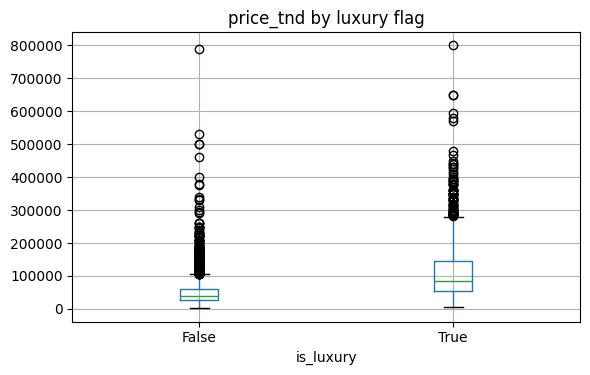

In [6]:
LUXURY_BRANDS = {"Porsche", "Land Rover", "Jaguar", "Mercedes-Benz", "BMW", "Audi"}

df["is_luxury"] = df["make"].isin(LUXURY_BRANDS)
print(df["is_luxury"].value_counts())
print(f"Luxury share: {df['is_luxury'].mean():.1%}")

fig, ax = plt.subplots(figsize=(6,4))
df.boxplot(column="price_tnd", by="is_luxury", ax=ax)
ax.set_title("price_tnd by luxury flag")
plt.suptitle("")
plt.tight_layout()
plt.show()

## 4. Segment-aware IQR outlier removal (luxury/regular-aware)

**Why the v2 outlier check wasn't enough for luxury**: it required at least 10 rows in a
`make`+`model` group before checking for outliers at all. Luxury models are far more fragmented
(e.g. many BMW/Mercedes trims with under 10 listings each), so most luxury rows were never
actually checked in v2.

**v3 fix**:
- IQR computed on **log1p(price)**, not raw price — price is right-skewed, especially for luxury,
  so log-space bounds are more meaningful and less dominated by the upper tail.
- Groups with fewer than `min_group_size` rows **fall back to the luxury/regular segment-level
  IQR** instead of being skipped — every row now gets checked against *some* IQR.
- Luxury uses a **tighter** multiplier (`k=1.5`) than regular (`k=2.5`), since price errors/typos
  are more costly in the luxury segment and the goal here is specifically to bring luxury MAE/MAPE
  down.

In [7]:
def compute_iqr_bounds(values_log, k):
    q1, q3 = values_log.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k*iqr, q3 + k*iqr


def flag_luxury_aware_outliers(frame, group_cols=("make", "model"), price_col="price_tnd",
                                segment_col="is_luxury", min_group_size=10,
                                k_by_segment=None):
    if k_by_segment is None:
        k_by_segment = {True: 1.5, False: 2.5}

    log_price = np.log1p(frame[price_col])
    group_key = frame[list(group_cols)].astype(str).agg("_".join, axis=1)
    group_sizes = group_key.map(group_key.value_counts())

    # segment-level (luxury / regular) fallback bounds, in log space
    segment_bounds = {
        seg: compute_iqr_bounds(log_price[frame[segment_col] == seg], k_by_segment[seg])
        for seg in frame[segment_col].unique()
    }

    outlier_mask = pd.Series(False, index=frame.index)
    for seg in frame[segment_col].unique():
        seg_mask = frame[segment_col] == seg
        k = k_by_segment[seg]

        # rows with a big-enough make+model group: use that group's own IQR
        big_group_mask = seg_mask & (group_sizes >= min_group_size)
        for key, idx in group_key[big_group_mask].groupby(group_key[big_group_mask]).groups.items():
            lo, hi = compute_iqr_bounds(log_price.loc[idx], k)
            outlier_mask.loc[idx] = (log_price.loc[idx] < lo) | (log_price.loc[idx] > hi)

        # rows whose make+model group is too small: fall back to the segment-level bounds
        small_group_mask = seg_mask & (group_sizes < min_group_size)
        lo, hi = segment_bounds[seg]
        outlier_mask.loc[small_group_mask] = (
            (log_price.loc[small_group_mask] < lo) | (log_price.loc[small_group_mask] > hi)
        )

    return outlier_mask


outlier_mask = flag_luxury_aware_outliers(df)
print("Outliers flagged, regular:", (outlier_mask & ~df["is_luxury"]).sum(),
      f"of {(~df['is_luxury']).sum()} regular rows")
print("Outliers flagged, luxury: ", (outlier_mask & df["is_luxury"]).sum(),
      f"of {df['is_luxury'].sum()} luxury rows")

before = df.shape[0]
df = df[~outlier_mask].reset_index(drop=True)
print(f"\nDropped {before - df.shape[0]} outlier rows total -> {df.shape[0]} rows remain")

Outliers flagged, regular: 87 of 8326 regular rows
Outliers flagged, luxury:  41 of 1888 luxury rows

Dropped 128 outlier rows total -> 10086 rows remain


## 5. Recovering signal from Unknown `fuel_type` / `transmission` / `body_type`

These three columns have a lot of `"Unknown"` values because not every source site captured them:
`fuel_type` 4.2% Unknown, `transmission` 28.8% Unknown, `body_type` 51.6% Unknown. Text-mining
`title_raw` barely helps (titles are almost always just "Make Model", e.g. "Volkswagen Polo" —
recovers under 10% of missing fuel_type and under 2% of missing body_type).

**What actually works**: most cars of the same `make`+`model` share the same fuel type,
transmission, and body style (e.g. almost every "Clio 5" is a hatchback). So we impute Unknown
values using the most common non-Unknown value for that `make`+`model`, falling back to `make`-level
mode, then the global mode, if the model itself has no known examples. Coverage: this recovers a
real value for ~43% of Unknown fuel_type rows, ~67% of Unknown transmission rows, and ~45% of
Unknown body_type rows.

We also keep a `*_was_unknown` flag per column — imputed values are still less certain than
directly observed ones, and the model can learn to weight them differently.

In [8]:
IMPUTE_COLS = ["fuel_type", "transmission", "body_type"]

def mode_or_none(s):
    s = s[s != "Unknown"]
    return s.mode().iloc[0] if not s.empty else None

make_model_key = df["make"].str.strip() + " " + df["model"].str.strip()
impute_maps = {}

for col in IMPUTE_COLS:
    df[f"{col}_was_unknown"] = (df[col] == "Unknown").astype(int)

    model_mode = df.groupby(make_model_key)[col].agg(mode_or_none)
    make_mode = df.groupby("make")[col].agg(mode_or_none)
    global_mode = df.loc[df[col] != "Unknown", col].mode().iloc[0]
    impute_maps[col] = {"model_mode": model_mode.to_dict(), "make_mode": make_mode.to_dict(),
                         "global_mode": global_mode}

    is_unknown = df[col] == "Unknown"
    filled = df[col].copy()
    filled.loc[is_unknown] = make_model_key.loc[is_unknown].map(model_mode)
    still_unknown = filled == "Unknown"
    still_missing = filled.isna() | still_unknown
    filled.loc[still_missing] = df.loc[still_missing, "make"].map(make_mode)
    filled = filled.fillna(global_mode)
    filled = filled.replace("Unknown", global_mode)

    n_recovered = (is_unknown & (filled != "Unknown")).sum()
    print(f"{col}: recovered {n_recovered} of {is_unknown.sum()} Unknown rows "
          f"({n_recovered / max(is_unknown.sum(),1):.1%})")
    df[col] = filled

df[IMPUTE_COLS + [f"{c}_was_unknown" for c in IMPUTE_COLS]].head()

fuel_type: recovered 11 of 11 Unknown rows (100.0%)


transmission: recovered 2672 of 2672 Unknown rows (100.0%)


body_type: recovered 4849 of 4849 Unknown rows (100.0%)


,fuel_type,transmission,body_type,fuel_type_was_unknown,transmission_was_unknown,body_type_was_unknown
0,Petrol,Manual,Compacte,0,0,1
1,Diesel,Manual,Minivan,0,0,1
2,Petrol,Manual,Compacte,0,0,1
3,Petrol,Manual,Sedan,0,0,1
4,Petrol,Manual,Compacte,0,0,1


## 6. Feature engineering

All features are computable for a brand-new listing at prediction time.

In [9]:
df["vehicle_age"] = (CURRENT_YEAR - df["year"]).clip(lower=0)
df["km_per_year"] = df["mileage_km"] / df["vehicle_age"].replace(0, 1)
df["make_model"] = df["make"].str.strip() + " " + df["model"].str.strip()

df["listing_year"] = df["listing_date"].dt.year
df["listing_month"] = df["listing_date"].dt.month
df["listing_year"] = df["listing_year"].fillna(df["listing_year"].median())
df["listing_month"] = df["listing_month"].fillna(df["listing_month"].median())

grand_tunis = {"Tunis", "Ariana", "Ben Arous", "Manouba"}
coastal = {"Sousse", "Sfax", "Monastir", "Nabeul", "Bizerte", "Mahdia", "Gabès"}
def region_group(r):
    if r in grand_tunis:
        return "Grand Tunis"
    if r in coastal:
        return "Coastal"
    return "Interior/South"
df["region_group"] = df["region"].apply(region_group)

keywords = ["GT", "Sport", "Automatic", "Cuir", "Leather", "Camera", "Toit", "4x4", "Line"]
for kw in keywords:
    df[f"title_has_{kw.lower()}"] = df["title_raw"].str.contains(kw, case=False, na=False).astype(int)

feature_cols_num = ["vehicle_age", "mileage_km", "km_per_year", "listing_year", "listing_month"] \
    + [c for c in df.columns if c.startswith("title_has_")] \
    + [f"{c}_was_unknown" for c in IMPUTE_COLS]
feature_cols_cat = ["make_model", "fuel_type", "transmission", "body_type", "region_group", "seller_type"]
FEATURES = feature_cols_num + feature_cols_cat
TARGET = "price_tnd"

df = df.sort_values("listing_date").reset_index(drop=True)
df[["is_luxury"] + FEATURES + [TARGET]].head()

,is_luxury,vehicle_age,mileage_km,km_per_year,listing_year,listing_month,title_has_gt,title_has_sport,title_has_automatic,title_has_cuir,title_has_leather,title_has_camera,title_has_toit,title_has_4x4,title_has_line,fuel_type_was_unknown,transmission_was_unknown,body_type_was_unknown,make_model,fuel_type,transmission,body_type,region_group,seller_type,price_tnd
0,True,17,200000,11764.705882,2021.0,6.0,0,0,0,0,0,0,0,0,0,0,0,1,BMW Série 3,Diesel,Manual,Sedan,Grand Tunis,Private,33000
1,False,20,190000,9500.000000,2021.0,6.0,0,0,0,0,0,0,0,0,0,0,0,1,Citroen C3,Petrol,Manual,Compacte,Grand Tunis,Private,19000
2,False,16,94500,5906.250000,2021.0,6.0,0,0,0,0,0,0,0,0,0,0,0,1,Opel Corsa,Diesel,Manual,Compacte,Interior/South,Pro,33300
3,False,12,78000,6500.000000,2021.0,6.0,0,0,0,0,0,0,0,0,0,0,0,1,Dacia Sandero,Petrol,Manual,Compacte,Interior/South,Private,38000
4,False,12,169000,14083.333333,2021.0,6.0,0,0,0,0,0,0,0,0,0,0,0,1,Renault Symbol,Petrol,Manual,Sedan,Grand Tunis,Private,30000


## 7. Reusable helpers (split, rare-category collapsing, baseline, evaluation)

Same logic as v1, wrapped into functions so we can run it once for the regular segment and once
for the luxury segment.

In [10]:
class RareCategoryCollapser(BaseEstimator, TransformerMixin):
    """Map categories seen fewer than min_count times in the training data to 'other'."""
    def __init__(self, cols, min_count=20):
        self.cols = cols
        self.min_count = min_count

    def fit(self, X, y=None):
        X = pd.DataFrame(X, columns=self.cols)
        self.keep_ = {c: set(X[c].value_counts()[lambda s: s >= self.min_count].index) for c in self.cols}
        return self

    def transform(self, X):
        X = pd.DataFrame(X, columns=self.cols).copy()
        for c in self.cols:
            X[c] = X[c].where(X[c].isin(self.keep_[c]), "other")
        return X


def time_split(segment_df, train_frac=0.70, val_frac=0.15):
    n = len(segment_df)
    train_end = int(n * train_frac)
    val_end = int(n * (train_frac + val_frac))
    return segment_df.iloc[:train_end], segment_df.iloc[train_end:val_end], segment_df.iloc[val_end:]


def evaluate(y_true, y_pred, label=""):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mape = mean_absolute_percentage_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    return {"segment": label, "MAE": mae, "RMSE": rmse, "MAPE": mape, "R2": r2, "n": len(y_true)}


def median_baseline(train_df, eval_df, min_count=1):
    key_train = train_df["make_model"] + "_" + train_df["year"].astype(str)
    lookup = train_df.groupby(key_train)["price_tnd"].median()
    overall_median = train_df["price_tnd"].median()
    key_eval = eval_df["make_model"] + "_" + eval_df["year"].astype(str)
    return key_eval.map(lookup).fillna(overall_median)


def prep_lgb_frame(X, cat_cols, collapser, fit=False):
    X = X.copy()
    if fit:
        collapser.fit(X[cat_cols])
    X[cat_cols] = collapser.transform(X[cat_cols])
    for c in cat_cols:
        X[c] = X[c].astype("category")
    return X


def align_categories(X_ref, *others):
    cats = {c: pd.Categorical(X_ref[c]).categories for c in X_ref.columns if str(X_ref[c].dtype) == "category"}
    out = [X_ref]
    for X in others:
        X = X.copy()
        for c, cat in cats.items():
            X[c] = pd.Categorical(X[c], categories=cat)
        out.append(X)
    return out


def tune_lightgbm(X_trainval, y_trainval_log, cat_cols, n_trials=8, n_splits=5, seed=RANDOM_STATE):
    from sklearn.model_selection import KFold
    param_grid = {
        "num_leaves": [15, 31, 63],
        "learning_rate": [0.03, 0.05, 0.08],
        "min_child_samples": [5, 10, 20],
    }
    combos = list(product(param_grid["num_leaves"], param_grid["learning_rate"], param_grid["min_child_samples"]))
    rng = np.random.RandomState(seed)
    sample_combos = [combos[i] for i in rng.choice(len(combos), size=min(n_trials, len(combos)), replace=False)]

    kf = KFold(n_splits=n_splits, shuffle=True, random_state=seed)
    results = []
    for nl, lr, mcs in sample_combos:
        maes = []
        for tr_idx, va_idx in kf.split(X_trainval):
            X_tr, X_va = X_trainval.iloc[tr_idx], X_trainval.iloc[va_idx]
            y_tr, y_va = y_trainval_log.iloc[tr_idx], y_trainval_log.iloc[va_idx]
            dtrain = lgb.Dataset(X_tr, label=y_tr, categorical_feature=cat_cols, free_raw_data=False)
            dval = lgb.Dataset(X_va, label=y_va, categorical_feature=cat_cols, reference=dtrain, free_raw_data=False)
            params = {
                "objective": "regression_l1", "metric": "mae", "verbose": -1, "seed": seed,
                "feature_fraction": 0.8, "bagging_fraction": 0.8, "bagging_freq": 1,
                "num_leaves": nl, "learning_rate": lr, "min_child_samples": mcs,
            }
            m = lgb.train(params, dtrain, num_boost_round=1000,
                           valid_sets=[dval], callbacks=[lgb.early_stopping(30, verbose=False)])
            pred = m.predict(X_va, num_iteration=m.best_iteration)
            maes.append(mean_absolute_error(y_va, pred))
        results.append({"num_leaves": nl, "learning_rate": lr, "min_child_samples": mcs,
                         "cv_mae_log": float(np.mean(maes))})
    results_df = pd.DataFrame(results).sort_values("cv_mae_log")
    best = results_df.iloc[0][["num_leaves","learning_rate","min_child_samples"]].to_dict()
    best = {"num_leaves": int(best["num_leaves"]), "learning_rate": float(best["learning_rate"]),
            "min_child_samples": int(best["min_child_samples"])}
    return best, results_df

## 8. Train the regular-car pipeline

In [11]:
reg_df = df[~df["is_luxury"]].reset_index(drop=True)
print("Regular segment:", reg_df.shape)

reg_train, reg_val, reg_test = time_split(reg_df)
X_reg_train, y_reg_train = reg_train[FEATURES], reg_train[TARGET]
X_reg_val, y_reg_val = reg_val[FEATURES], reg_val[TARGET]
X_reg_test, y_reg_test = reg_test[FEATURES], reg_test[TARGET]

y_reg_train_log = np.log1p(y_reg_train)
y_reg_val_log = np.log1p(y_reg_val)

reg_baseline_pred = median_baseline(reg_train, reg_test)
reg_baseline_metrics = evaluate(y_reg_test, reg_baseline_pred, "Regular - baseline")
reg_baseline_metrics

Regular segment: (8239, 32)


{'segment': 'Regular - baseline',
 'MAE': 13611.814724919093,
 'RMSE': np.float64(23581.88119208142),
 'MAPE': 0.3346092132881192,
 'R2': 0.3031496165098465,
 'n': 1236}

In [12]:
reg_collapser = RareCategoryCollapser(cols=feature_cols_cat, min_count=20)
X_reg_train_lgb = prep_lgb_frame(X_reg_train, feature_cols_cat, reg_collapser, fit=True)
X_reg_val_lgb, X_reg_test_lgb = align_categories(
    X_reg_train_lgb,
    prep_lgb_frame(X_reg_val, feature_cols_cat, reg_collapser),
    prep_lgb_frame(X_reg_test, feature_cols_cat, reg_collapser),
)[1:]
X_reg_train_lgb = align_categories(X_reg_train_lgb)[0]

reg_best_params, reg_cv_results = tune_lightgbm(
    pd.concat([X_reg_train_lgb, X_reg_val_lgb]),
    pd.concat([y_reg_train_log, y_reg_val_log]),
    feature_cols_cat, n_trials=8,
)
print("Best params (regular):", reg_best_params)
reg_cv_results

Best params (regular): {'num_leaves': 31, 'learning_rate': 0.05, 'min_child_samples': 10}


,num_leaves,learning_rate,min_child_samples,cv_mae_log
1,31,0.05,10,0.174993
4,15,0.03,5,0.175507
6,31,0.08,10,0.175569
7,31,0.08,20,0.175621
0,15,0.08,20,0.175731
2,31,0.03,5,0.175824
5,31,0.03,20,0.176019
3,63,0.05,5,0.176090


In [13]:
reg_final_params = {
    "objective": "regression_l1", "metric": "mae", "verbose": -1, "seed": RANDOM_STATE,
    "feature_fraction": 0.8, "bagging_fraction": 0.8, "bagging_freq": 1,
    **reg_best_params,
}
X_reg_trainval_lgb = pd.concat([X_reg_train_lgb, X_reg_val_lgb])
y_reg_trainval_log = pd.concat([y_reg_train_log, y_reg_val_log])
dtrain_reg = lgb.Dataset(X_reg_trainval_lgb, label=y_reg_trainval_log,
                          categorical_feature=feature_cols_cat, free_raw_data=False)
reg_model = lgb.train(reg_final_params, dtrain_reg, num_boost_round=800)

reg_pred = np.expm1(reg_model.predict(X_reg_test_lgb))
reg_model_metrics = evaluate(y_reg_test, reg_pred, "Regular - LightGBM")
reg_model_metrics

{'segment': 'Regular - LightGBM',
 'MAE': 10644.529683935545,
 'RMSE': np.float64(17228.144669679343),
 'MAPE': 0.2666653051206531,
 'R2': 0.6280713195088437,
 'n': 1236}

## 9. Train the luxury-car pipeline

Same steps, smaller data (1,888 rows), lighter tuning grid to avoid overfitting a small segment.

In [14]:
lux_df = df[df["is_luxury"]].reset_index(drop=True)
print("Luxury segment:", lux_df.shape)

lux_train, lux_val, lux_test = time_split(lux_df)
X_lux_train, y_lux_train = lux_train[FEATURES], lux_train[TARGET]
X_lux_val, y_lux_val = lux_val[FEATURES], lux_val[TARGET]
X_lux_test, y_lux_test = lux_test[FEATURES], lux_test[TARGET]

y_lux_train_log = np.log1p(y_lux_train)
y_lux_val_log = np.log1p(y_lux_val)

lux_baseline_pred = median_baseline(lux_train, lux_test)
lux_baseline_metrics = evaluate(y_lux_test, lux_baseline_pred, "Luxury - baseline")
lux_baseline_metrics

Luxury segment: (1847, 32)


{'segment': 'Luxury - baseline',
 'MAE': 43159.561151079135,
 'RMSE': np.float64(64713.07652439187),
 'MAPE': 0.571532401079434,
 'R2': 0.11253865470776259,
 'n': 278}

In [15]:
lux_collapser = RareCategoryCollapser(cols=feature_cols_cat, min_count=10)
X_lux_train_lgb = prep_lgb_frame(X_lux_train, feature_cols_cat, lux_collapser, fit=True)
X_lux_val_lgb, X_lux_test_lgb = align_categories(
    X_lux_train_lgb,
    prep_lgb_frame(X_lux_val, feature_cols_cat, lux_collapser),
    prep_lgb_frame(X_lux_test, feature_cols_cat, lux_collapser),
)[1:]
X_lux_train_lgb = align_categories(X_lux_train_lgb)[0]

lux_best_params, lux_cv_results = tune_lightgbm(
    pd.concat([X_lux_train_lgb, X_lux_val_lgb]),
    pd.concat([y_lux_train_log, y_lux_val_log]),
    feature_cols_cat, n_trials=8, n_splits=4,
)
print("Best params (luxury):", lux_best_params)
lux_cv_results

Best params (luxury): {'num_leaves': 15, 'learning_rate': 0.03, 'min_child_samples': 5}


,num_leaves,learning_rate,min_child_samples,cv_mae_log
4,15,0.03,5,0.192013
2,31,0.03,5,0.193229
0,15,0.08,20,0.193275
1,31,0.05,10,0.193962
6,31,0.08,10,0.194727
5,31,0.03,20,0.194734
7,31,0.08,20,0.195739
3,63,0.05,5,0.201521


In [16]:
lux_final_params = {
    "objective": "regression_l1", "metric": "mae", "verbose": -1, "seed": RANDOM_STATE,
    "feature_fraction": 0.8, "bagging_fraction": 0.8, "bagging_freq": 1,
    **lux_best_params,
}
X_lux_trainval_lgb = pd.concat([X_lux_train_lgb, X_lux_val_lgb])
y_lux_trainval_log = pd.concat([y_lux_train_log, y_lux_val_log])
dtrain_lux = lgb.Dataset(X_lux_trainval_lgb, label=y_lux_trainval_log,
                          categorical_feature=feature_cols_cat, free_raw_data=False)
lux_model = lgb.train(lux_final_params, dtrain_lux, num_boost_round=800)

lux_pred = np.expm1(lux_model.predict(X_lux_test_lgb))
lux_model_metrics = evaluate(y_lux_test, lux_pred, "Luxury - LightGBM")
lux_model_metrics

{'segment': 'Luxury - LightGBM',
 'MAE': 24909.25919496799,
 'RMSE': np.float64(38972.14256078606),
 'MAPE': 0.2832992614783724,
 'R2': 0.6781348791067672,
 'n': 278}

## 10. Final block — combined outcome vs baseline, overall and by segment

This stitches both segments' test predictions back together to answer: *how much did we actually
improve on the baseline, and where?*

In [17]:
results_table = pd.DataFrame([
    reg_baseline_metrics, reg_model_metrics,
    lux_baseline_metrics, lux_model_metrics,
]).set_index("segment")

# Overall (regular + luxury combined), baseline vs model
overall_baseline_pred = pd.concat([reg_baseline_pred, lux_baseline_pred])
overall_model_pred = pd.concat([pd.Series(reg_pred, index=y_reg_test.index),
                                 pd.Series(lux_pred, index=y_lux_test.index)])
overall_y_true = pd.concat([y_reg_test, y_lux_test])

overall_baseline_metrics = evaluate(overall_y_true, overall_baseline_pred, "Overall - baseline")
overall_model_metrics = evaluate(overall_y_true, overall_model_pred, "Overall - model (routed)")

results_table = pd.concat([
    results_table,
    pd.DataFrame([overall_baseline_metrics, overall_model_metrics]).set_index("segment"),
])
results_table["MAE"] = results_table["MAE"].round(0)
results_table["RMSE"] = results_table["RMSE"].round(0)
results_table["MAPE"] = (results_table["MAPE"] * 100).round(1)
results_table["R2"] = results_table["R2"].round(3)
results_table.columns = ["MAE (TND)", "RMSE (TND)", "MAPE (%)", "R2", "n"]
results_table

,MAE (TND),RMSE (TND),MAPE (%),R2,n
segment,,,,,
Regular - baseline,13612.0,23582.0,33.5,0.303,1236
Regular - LightGBM,10645.0,17228.0,26.7,0.628,1236
Luxury - baseline,43160.0,64713.0,57.2,0.113,278
Luxury - LightGBM,24909.0,38972.0,28.3,0.678,278
Overall - baseline,19037.0,34971.0,37.8,0.374,1514
Overall - model (routed),13264.0,22830.0,27.0,0.733,1514


In [18]:
# % improvement of model over baseline, per segment
def pct_improvement(base_val, model_val):
    return (base_val - model_val) / base_val * 100

improvement_rows = []
for seg, base_metrics, model_metrics in [
    ("Regular", reg_baseline_metrics, reg_model_metrics),
    ("Luxury", lux_baseline_metrics, lux_model_metrics),
    ("Overall", overall_baseline_metrics, overall_model_metrics),
]:
    improvement_rows.append({
        "segment": seg,
        "MAE improvement %": round(pct_improvement(base_metrics["MAE"], model_metrics["MAE"]), 1),
        "RMSE improvement %": round(pct_improvement(base_metrics["RMSE"], model_metrics["RMSE"]), 1),
        "baseline MAE": round(base_metrics["MAE"]),
        "model MAE": round(model_metrics["MAE"]),
    })
pd.DataFrame(improvement_rows).set_index("segment")

,MAE improvement %,RMSE improvement %,baseline MAE,model MAE
segment,,,,
Regular,21.8,26.9,13612,10645
Luxury,42.3,39.8,43160,24909
Overall,30.3,34.7,19037,13264


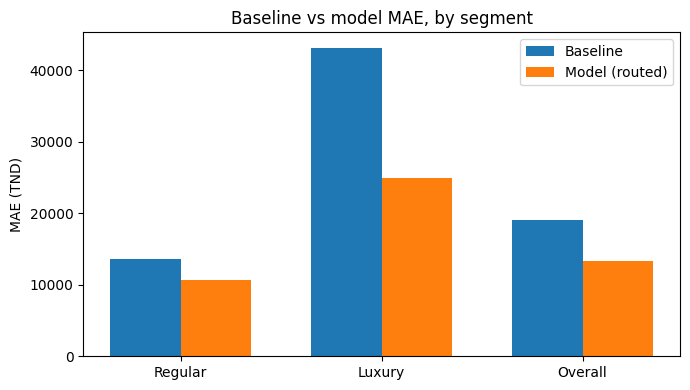

In [19]:
fig, ax = plt.subplots(figsize=(7,4))
labels = ["Regular", "Luxury", "Overall"]
baseline_maes = [reg_baseline_metrics["MAE"], lux_baseline_metrics["MAE"], overall_baseline_metrics["MAE"]]
model_maes = [reg_model_metrics["MAE"], lux_model_metrics["MAE"], overall_model_metrics["MAE"]]
x = np.arange(len(labels)); width = 0.35
ax.bar(x - width/2, baseline_maes, width, label="Baseline")
ax.bar(x + width/2, model_maes, width, label="Model (routed)")
ax.set_xticks(x); ax.set_xticklabels(labels)
ax.set_ylabel("MAE (TND)"); ax.set_title("Baseline vs model MAE, by segment")
ax.legend()
plt.tight_layout()
plt.show()

## 11. Error analysis (per segment)

In [20]:
def error_report(test_df_seg, y_true, y_pred, label):
    seg_analysis = test_df_seg.copy()
    seg_analysis["pred"] = np.asarray(y_pred)
    seg_analysis["abs_error"] = (seg_analysis["pred"] - y_true.values).__abs__()
    print(f"--- {label}: worst 5 makes by MAE ---")
    print(seg_analysis.groupby("make")["abs_error"].mean().sort_values(ascending=False).head(5))
    return seg_analysis

reg_analysis = error_report(reg_test, y_reg_test, reg_pred, "Regular")
print()
lux_analysis = error_report(lux_test, y_lux_test, lux_pred, "Luxury")

--- Regular: worst 5 makes by MAE ---
make
Volvo      53782.936368
Isuzu      29671.903401
Jeep       27059.601084
Unknown    26182.033479
Honda      24496.711131
Name: abs_error, dtype: float64

--- Luxury: worst 5 makes by MAE ---
make
Porsche          55093.840221
Jaguar           46749.322796
Land Rover       32987.578549
Mercedes-Benz    26439.348223
Audi             20151.693551
Name: abs_error, dtype: float64


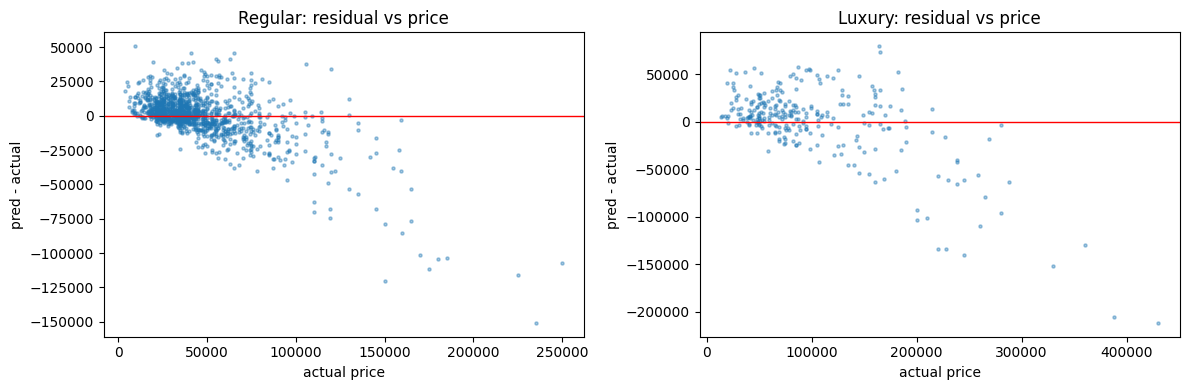

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12,4))
axes[0].scatter(reg_analysis["price_tnd"], reg_analysis["pred"] - reg_analysis["price_tnd"], s=5, alpha=0.4)
axes[0].axhline(0, color="red", lw=1)
axes[0].set_title("Regular: residual vs price"); axes[0].set_xlabel("actual price"); axes[0].set_ylabel("pred - actual")

axes[1].scatter(lux_analysis["price_tnd"], lux_analysis["pred"] - lux_analysis["price_tnd"], s=5, alpha=0.4)
axes[1].axhline(0, color="red", lw=1)
axes[1].set_title("Luxury: residual vs price"); axes[1].set_xlabel("actual price"); axes[1].set_ylabel("pred - actual")
plt.tight_layout()
plt.show()

## 12. Guard against the classic traps — recap (v4)

- ✅ `source_deal_label` dropped at load time (target leakage).
- ✅ **Fixed**: New-car rows removed *before* segment-outlier detection, not after.
- ✅ **New in v3**: outlier IQR is luxury/regular-aware and computed on log-price; small
  make+model groups fall back to segment-level bounds instead of skipping outlier checks.
- ✅ **New in v4**: `fuel_type`/`transmission`/`body_type` Unknowns imputed from `make`+`model`
  history rather than left as an opaque "Unknown" bucket, with a was-imputed flag kept as a
  feature so the model can weigh imputed values differently from observed ones.
- ✅ Luxury segment modeled separately, routed by brand tier (computable pre-sale, no price leakage).
- ✅ Encoders/rare-category collapsing fit on train only, per segment.
- ✅ Time-based split per segment + a single final test evaluation.
- ✅ Log1p target for both models so within-segment price spread doesn't dominate the loss.
- ✅ Final block reports baseline vs model, per segment and combined — no cherry-picked number.

## 13. Package, deploy & monitor

In [22]:
import joblib, json, os
from datetime import datetime

ARTIFACT_DIR = "artifacts"
os.makedirs(ARTIFACT_DIR, exist_ok=True)

joblib.dump({
    "regular_model": reg_model, "regular_collapser": reg_collapser,
    "luxury_model": lux_model, "luxury_collapser": lux_collapser,
    "luxury_brands": LUXURY_BRANDS,
    "feature_cols_num": feature_cols_num, "feature_cols_cat": feature_cols_cat,
    "region_group_fn": region_group, "keyword_flags": keywords,
    "impute_cols": IMPUTE_COLS, "impute_maps": impute_maps,
    "target_transform": "log1p",
}, f"{ARTIFACT_DIR}/model_pipeline_v4.joblib")

metadata = {
    "trained_at": datetime.now().isoformat(),
    "features_numeric": feature_cols_num,
    "features_categorical": feature_cols_cat,
    "luxury_brands": sorted(LUXURY_BRANDS),
    "metrics_test": {k: v for k, v in results_table.to_dict(orient="index").items()},
}
with open(f"{ARTIFACT_DIR}/model_metadata_v4.json", "w") as f:
    json.dump(metadata, f, indent=2, default=str)

print("Saved model_pipeline_v4.joblib and model_metadata_v4.json")

Saved model_pipeline_v4.joblib and model_metadata_v4.json


In [23]:
def predict_price(listing: dict) -> dict:
    """
    listing: dict with keys make, model, year, mileage_km, region, seller_type,
             and OPTIONALLY fuel_type, transmission, body_type (pass "Unknown" or omit
             if not known — they'll be imputed the same way training data was),
             listing_date (optional), title_raw (optional).
    Routes to the luxury or regular model based on brand tier, returns predicted_price + confidence.
    """
    art = joblib.load(f"{ARTIFACT_DIR}/model_pipeline_v4.joblib")
    row = {}
    age = max(CURRENT_YEAR - listing["year"], 0)
    row["vehicle_age"] = age
    row["mileage_km"] = listing["mileage_km"]
    row["km_per_year"] = listing["mileage_km"] / max(age, 1)
    ld = pd.to_datetime(listing.get("listing_date", pd.Timestamp.today()))
    row["listing_year"] = ld.year
    row["listing_month"] = ld.month
    title = listing.get("title_raw", "")
    for kw in art["keyword_flags"]:
        row[f"title_has_{kw.lower()}"] = int(kw.lower() in str(title).lower())

    make_s, model_s = listing["make"].strip(), listing["model"].strip()
    make_model_s = f"{make_s} {model_s}"
    row["make_model"] = make_model_s

    # impute fuel_type / transmission / body_type the same way training data was, if unknown/missing
    for col in art["impute_cols"]:
        val = listing.get(col, "Unknown")
        was_unknown = (val == "Unknown") or (val is None)
        if was_unknown:
            maps = art["impute_maps"][col]
            val = maps["model_mode"].get(make_model_s)
            if val is None:
                val = maps["make_mode"].get(make_s)
            if val is None:
                val = maps["global_mode"]
        row[col] = val
        row[f"{col}_was_unknown"] = int(was_unknown)

    row["region_group"] = art["region_group_fn"](listing["region"])
    row["seller_type"] = listing["seller_type"]

    X_new = pd.DataFrame([row])[art["feature_cols_num"] + art["feature_cols_cat"]]
    is_luxury = make_s in art["luxury_brands"]
    model = art["luxury_model"] if is_luxury else art["regular_model"]
    collapser = art["luxury_collapser"] if is_luxury else art["regular_collapser"]

    X_new[art["feature_cols_cat"]] = collapser.transform(X_new[art["feature_cols_cat"]])
    for c in art["feature_cols_cat"]:
        X_new[c] = X_new[c].astype("category")

    pred = float(np.expm1(model.predict(X_new))[0])
    is_other = (X_new["make_model"] == "other").iloc[0]
    confidence = "low" if is_other else "normal"

    return {"predicted_price_tnd": round(pred, -2), "segment": "luxury" if is_luxury else "regular",
            "confidence": confidence}

# example: fuel/transmission/body_type known
predict_price({
    "make": "Mercedes-Benz", "model": "C-Class", "year": 2018, "mileage_km": 90000,
    "fuel_type": "Diesel", "transmission": "Automatic", "body_type": "Sedan",
    "region": "Tunis", "seller_type": "Dealer",
})

{'predicted_price_tnd': 128200.0, 'segment': 'luxury', 'confidence': 'normal'}

In [24]:
# example: fuel/transmission/body_type unknown -> imputed automatically
predict_price({
    "make": "Renault", "model": "Clio 5", "year": 2020, "mileage_km": 60000,
    "region": "Sfax", "seller_type": "Private",
})

{'predicted_price_tnd': 42900.0, 'segment': 'regular', 'confidence': 'low'}

### Next steps

- Wrap `predict_price` in a FastAPI/Flask endpoint; it already routes by brand automatically.
- Log every prediction + eventual sale price; recompute rolling 30-day MAE per segment.
- Retrain monthly; revisit the `LUXURY_BRANDS` list periodically as market composition shifts.
- If the luxury segment stays noisy even after this split, consider quantile regression
  (predict a price *range* instead of a point estimate) — luxury pricing is inherently more variable.